# Beyond RFM: product-aware household clustering

**Midterm topic 10 — Grocery Store Dataset (Transaction & Product).**

Research question: do shopping-behavior and product-category features provide reproducible household segments beyond a simple RFM baseline? This notebook downloads the actual public Kaggle archive if needed and runs independently of supporting scripts. Run all cells in a fresh Jupyter or Colab session; allow several minutes and roughly 1 GB disk space. No Kaggle credentials were required at preparation time. If Kaggle later requires authentication, place `transaction_data.csv` and `product.csv` under `data/raw/`.

The calibration window is DAY 1–500; DAY 501–711 is untouched during feature construction and model selection. Household is the clustering unit. Later outcomes describe existing segments and are not evidence of causal or predictive value.

In [1]:
# Install only if dependencies are unavailable. For a repository checkout, requirements-lock.txt records the verified environment.
import importlib.util, subprocess, sys
packages={'pandas':'pandas','numpy':'numpy','scipy':'scipy','sklearn':'scikit-learn','matplotlib':'matplotlib'}
missing=[p for module,p in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])
import os
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')

'1'

## Design and checks

The source tables are linked by PRODUCT_ID with an explicit many-to-one validation. Nonpositive quantity or recorded sales value rows are excluded from positive-purchase analysis; the exclusion count is audited. Source discounts remain signed and are used only as an indicator of recorded discount activity. No arbitrary calendar date is invented from DAY.

RFM comprises recency, distinct baskets, and recorded sales. Behavior adds mean basket value, mean basket lines, unique-product breadth, department breadth, and fraction of transaction lines recording a discount. Positive count/value features use log(1+x), followed by calibration-only standardization. Product adds square-root spend shares for the eight largest calibration departments plus OTHER. Its centered composition block is weighted to equal the total variance of the behavior block, with 0.5× and 2× sensitivity checks.

KMeans and Ward use k=2…8. DBSCAN uses min_samples=10 and four calibration 10-neighbor-distance quantiles for eps; noise and valid cluster count accompany scores. Silhouette and DBI are compared within a feature space. KMeans k is selected independently within each space by maximum silhouette, requiring each cluster to contain at least 5% of households. A fixed-k=3 ablation prevents differing cluster counts from confounding feature comparisons.

Stability includes 20 single-initialization KMeans fits and 20 paired 80% subsample refits. ARI uses only shared household IDs; identical sampled IDs are used across feature spaces. Calibration preprocessing is held fixed, so this measures clustering sensitivity, not full-pipeline uncertainty. Holdout bootstrap intervals are conditional on the fixed fitted labels.

In [2]:
"""Reproducible household clustering; run from project root."""

from pathlib import Path
import json, hashlib, zipfile, urllib.request, platform, importlib.metadata, os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/pythsn-mpl")
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import kruskal
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

ROOT = Path.cwd()
RAW = ROOT / "data/raw"
OUT = ROOT / "results"
FIG = ROOT / "figures"
for p in [RAW, OUT, FIG]:
    p.mkdir(parents=True, exist_ok=True)
URL = "https://www.kaggle.com/api/v1/datasets/download/frtgnn/dunnhumby-the-complete-journey"


def acquire():
    if (
        not (RAW / "transaction_data.csv").exists()
        or not (RAW / "product.csv").exists()
    ):
        z = RAW / "dunnhumby.zip"
        if not z.exists():
            urllib.request.urlretrieve(URL, z)
        with zipfile.ZipFile(z) as f:
            for name in ["transaction_data.csv", "product.csv"]:
                f.extract(name, RAW)


def align_labels(reference, candidate):
    """Relabel a same-k partition to maximize household agreement."""
    reference_ids, ri = np.unique(reference, return_inverse=True)
    candidate_ids, ci = np.unique(candidate, return_inverse=True)
    overlap = np.zeros((len(reference_ids), len(candidate_ids)), dtype=int)
    np.add.at(overlap, (ri, ci), 1)
    rows, cols = linear_sum_assignment(overlap, maximize=True)
    mapping = dict(zip(candidate_ids[cols], reference_ids[rows]))
    return np.array([mapping[label] for label in candidate])


def household_cases(hh, composition, labels, product_features):
    """Choose one calibration representative per changed k=2 transition."""
    rfm = labels[("RFM", "KMeans", 2)]
    product = labels[("Product", "KMeans", 2)]
    aligned = align_labels(rfm, product)
    columns = ["recency", "frequency", "monetary", "mean_basket_value",
               "mean_basket_lines", "product_breadth", "department_breadth",
               "discount_line_share"]
    frame = hh[columns].join(composition).assign(
        rfm_cluster=rfm, product_cluster=product, product_aligned_cluster=aligned
    )
    counts = (
        frame.groupby(["rfm_cluster", "product_cluster", "product_aligned_cluster"])
        .size().rename("households").reset_index()
    )
    counts.to_csv(OUT / "rfm_product_transitions.csv", index=False)
    ids = []
    for transition in counts.itertuples():
        if transition.rfm_cluster == transition.product_aligned_cluster:
            continue
        members = np.flatnonzero(
            (rfm == transition.rfm_cluster) & (product == transition.product_cluster)
        )
        features = product_features[members]
        squared_distances = ((features - features.mean(axis=0)) ** 2).sum(axis=1)
        ids.append(members[np.argmin(squared_distances)])
    cases = frame.iloc[ids]
    cases.to_csv(OUT / "household_cases.csv")
    if cases.empty:
        return
    activity_group = {
        label: name
        for label, name in zip(
            hh.monetary.groupby(rfm).mean().sort_values().index, ["Lower", "Higher"]
        )
    }
    fig, axes = plt.subplots(len(cases), 1, figsize=(10, 3.45 * len(cases)), squeeze=False)
    fig.suptitle("How two calibration households change segments", weight="bold")
    for ax, (key, row) in zip(axes[:, 0], cases.iterrows()):
        source = int(row.rfm_cluster)
        destination = int(row.product_cluster)
        aligned_destination = int(row.product_aligned_cluster)
        profiles = [
            row[composition.columns].to_numpy(dtype=float),
            composition[rfm == source].mean().to_numpy(),
            composition[product == destination].mean().to_numpy(),
        ]
        x = np.arange(composition.shape[1])
        for i, (profile, label, color) in enumerate(zip(
            profiles,
            [f"Household {key}", "RFM source mean", "Product destination mean"],
            ["#0f766e", "#8497a8", "#d67c37"],
        )):
            ax.bar(x + (i - 1) * 0.25, 100 * profile, width=0.24, label=label, color=color)
        ax.set_title(
            f"Household {key}  |  {activity_group[source]}-activity RFM → "
            f"{activity_group[aligned_destination].lower()}-activity Product\n"
            f"{row.recency:.0f} days recency  ·  {row.frequency:.0f} baskets  ·  "
            f"{row.monetary:,.2f} recorded sales  ·  {row.product_breadth:.0f} distinct products",
            loc="left", fontsize=10,
        )
        ax.set_ylabel("Spend share (%)")
        ax.set_xticks(x, composition.columns, rotation=20, ha="right")
        ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG / "10_household_cases.png", bbox_inches="tight")
    plt.close(fig)


def weight_flow(assignments):
    """Export exact adjacent flows and draw bands proportional to their counts."""
    colors = ["#0f766e", "#4f6fa5", "#c87733"]
    counts = {
        weight: assignments[weight].value_counts().sort_index()
        for weight in assignments
    }
    n = len(assignments)
    gap = n * 0.045
    starts = {
        weight: sizes.cumsum().shift(fill_value=0) + gap * np.arange(len(sizes))
        for weight, sizes in counts.items()
    }
    fig, ax = plt.subplots(figsize=(9, 4.6))
    flows = []
    for x, (left, right) in enumerate(zip(assignments.columns[:-1], assignments.columns[1:])):
        pair = pd.crosstab(assignments[left], assignments[right])
        ari = adjusted_rand_score(assignments[left], assignments[right])
        switched = int((assignments[left] != assignments[right]).sum())
        ax.text(x + 0.5, n + 3.05 * gap, f"{switched:,} switched  ·  ARI {ari:.3f}",
                ha="center", va="bottom", fontsize=10)
        source_offsets = starts[left].copy()
        target_offsets = starts[right].copy()
        t = np.linspace(0, 1, 80)
        blend = t * t * (3 - 2 * t)
        for source in pair.index:
            for target in pair.columns:
                count = int(pair.loc[source, target])
                flows.append({
                    "from_weight": left, "to_weight": right,
                    "from_aligned_cluster": source, "to_aligned_cluster": target,
                    "households": count, "pairwise_ari": ari,
                    "pairwise_switched_households": switched,
                })
                lower = source_offsets[source] * (1 - blend) + target_offsets[target] * blend
                ax.fill_between(x + 0.048 + 0.904 * t, lower, lower + count,
                                color=colors[source], alpha=0.58, linewidth=0)
                source_offsets[source] += count
                target_offsets[target] += count
    for x, (weight, sizes) in enumerate(counts.items()):
        for cluster, size in sizes.items():
            start = starts[weight][cluster]
            ax.bar(x, size, bottom=start, width=0.096, color=colors[cluster], linewidth=0)
            ax.text(x, start + size / 2, f"{size:,}", color="white",
                    ha="center", va="center", weight="bold", fontsize=8)
        ax.text(x, -gap, f"{weight:g}×", ha="center", va="top", weight="bold")
    pd.DataFrame(flows).to_csv(OUT / "category_weight_flows.csv", index=False)
    ax.set(xlim=(-0.13, 2.13), ylim=(-2.2 * gap, n + 4.6 * gap))
    ax.axis("off")
    fig.suptitle("Household flows as category weight changes", weight="bold")
    fig.text(0.5, 0.01, "KMeans, k = 3  ·  Band width = households  ·  Labels aligned to the 1× fit",
             ha="center", color="#46566b")
    fig.tight_layout(rect=(0, 0.04, 1, 0.94))
    fig.savefig(FIG / "11_category_flow.png", bbox_inches="tight")
    plt.close(fig)


def category_eta_squared(shares, labels):
    """Fraction of total squared Euclidean dispersion between clusters."""
    center = shares.mean(axis=0)
    total = ((shares - center) ** 2).sum()
    if total == 0:
        return np.nan
    between = 0.0
    for cluster in np.unique(labels):
        subset = shares[labels == cluster]
        between += len(subset) * ((subset.mean(axis=0) - center) ** 2).sum()
    return between / total


def heldout_categories(future, composition, active, selected_labels):
    """Evaluate fixed labels on observed future household spend mixes."""
    top = composition.columns.drop("OTHER")
    spending = future.assign(
        category=future.DEPARTMENT.where(future.DEPARTMENT.isin(top), "OTHER")
    ).groupby(["household_key", "category"]).SALES_VALUE.sum().unstack(fill_value=0)
    later = spending.reindex(
        index=active.index[active], columns=composition.columns, fill_value=0
    )
    later = later.div(later.sum(axis=1), axis=0)
    earlier = composition.loc[later.index]
    later.to_csv(OUT / "holdout_category_household_shares.csv")
    profiles = []
    summary = []
    activity = []
    active_labels = {}
    for space, all_labels in selected_labels.items():
        labels = all_labels[active.to_numpy()]
        active_labels[space] = labels
        summary.append({
            "space": space, "k": len(np.unique(all_labels)),
            "calibration_households": len(active), "active_households": len(later),
            "calibration_category_eta_squared": category_eta_squared(earlier.to_numpy(), labels),
            "future_category_eta_squared": category_eta_squared(later.to_numpy(), labels),
        })
        for cluster in np.unique(all_labels):
            n = int((all_labels == cluster).sum())
            n_active = int((labels == cluster).sum())
            activity.append({
                "space": space, "cluster": cluster, "calibration_households": n,
                "active_households": n_active, "future_active_rate": n_active / n,
            })
            for period, shares in [("Calibration", earlier), ("Holdout", later)]:
                means = shares[labels == cluster].mean()
                for category, share in means.items():
                    profiles.append({
                        "space": space, "cluster": cluster, "period": period,
                        "category": category, "active_households": n_active,
                        "mean_household_share": share,
                        "deviation_from_active_mean": share - shares[category].mean(),
                    })
    pd.DataFrame(summary).to_csv(OUT / "holdout_category_summary.csv", index=False)
    pd.DataFrame(activity).to_csv(OUT / "holdout_category_activity.csv", index=False)
    profile_frame = pd.DataFrame(profiles)
    profile_frame.to_csv(OUT / "holdout_category_profiles.csv", index=False)

    values = later.to_numpy()
    rfm, product = active_labels["RFM"], active_labels["Product"]
    point = category_eta_squared(values, product) - category_eta_squared(values, rfm)
    rng = np.random.default_rng(2027)
    draws = []
    for _ in range(1000):
        ids = rng.integers(len(later), size=len(later))
        draws.append(
            category_eta_squared(values[ids], product[ids])
            - category_eta_squared(values[ids], rfm[ids])
        )
    low, high = np.quantile(draws, [0.025, 0.975])
    pd.DataFrame([{
        "comparison": "Product minus RFM", "active_households": len(later),
        "eta_squared_difference": point, "conditional_ci_low": low,
        "conditional_ci_high": high, "bootstrap_draws": len(draws),
    }]).to_csv(OUT / "holdout_category_paired_difference.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharey=True)
    vmax = max(1, 100 * profile_frame.deviation_from_active_mean.abs().max())
    for ax, period in zip(axes, ["Calibration", "Holdout"]):
        panel = profile_frame[profile_frame.period == period].pivot(
            index=["space", "cluster", "active_households"], columns="category",
            values="deviation_from_active_mean",
        ).reindex(columns=composition.columns).loc[list(selected_labels)]
        values = panel.to_numpy() * 100
        image = ax.imshow(values, cmap="RdBu_r", aspect="auto", vmin=-vmax, vmax=vmax)
        ax.set_title(period, weight="bold")
        ax.set_xticks(range(len(panel.columns)), panel.columns, rotation=32, ha="right")
        ax.set_yticks(range(len(panel)), [f"{s} {c} · n={n:,}" for s, c, n in panel.index])
        for i, j in np.ndindex(values.shape):
            value = values[i, j]
            ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(value) > 0.66 * vmax else "#192c40")
    fig.suptitle(f"Category profiles on the same {len(later):,} later-active households", weight="bold")
    fig.subplots_adjust(left=0.16, right=0.89, bottom=0.21, top=0.83, wspace=0.08)
    fig.colorbar(image, cax=fig.add_axes([0.91, 0.21, 0.014, 0.62]),
                 label="Percentage points from the period’s active-cohort mean")
    fig.savefig(FIG / "12_future_categories.png", bbox_inches="tight")
    plt.close(fig)


def run():
    acquire()
    tx = pd.read_csv(RAW / "transaction_data.csv")
    products = pd.read_csv(RAW / "product.csv")
    audit = {
        "raw_transaction_rows": len(tx),
        "raw_product_rows": len(products),
        "transaction_exact_duplicate_rows": int(tx.duplicated().sum()),
        "product_duplicate_keys": int(products.PRODUCT_ID.duplicated().sum()),
        "missing_transaction_cells": tx.isna().sum().to_dict(),
        "missing_product_cells": products.isna().sum().to_dict(),
        "day_min": int(tx.DAY.min()),
        "day_max": int(tx.DAY.max()),
        "households_raw": int(tx.household_key.nunique()),
        "nonpositive_quantity_rows": int((tx.QUANTITY <= 0).sum()),
        "nonpositive_sales_rows": int((tx.SALES_VALUE <= 0).sum()),
        "negative_retail_discount_rows": int((tx.RETAIL_DISC < 0).sum()),
    }
    assert products.PRODUCT_ID.is_unique
    # Exact repeated rows may represent legitimate repeated scans: retain and disclose.
    merged = tx.merge(
        products, on="PRODUCT_ID", how="left", validate="many_to_one", indicator=True
    )
    audit["unmatched_product_rows"] = int((merged["_merge"] != "both").sum())
    assert len(merged) == len(tx)
    merged["DEPARTMENT"] = (
        merged.DEPARTMENT.fillna("UNKNOWN").str.strip().replace("", "UNKNOWN")
    )
    clean = merged.loc[(merged.QUANTITY > 0) & (merged.SALES_VALUE > 0)].copy()
    audit["retained_rows"] = len(clean)
    audit["excluded_rows"] = len(tx) - len(clean)
    audit["basket_household_conflicts"] = int(
        (clean.groupby("BASKET_ID").household_key.nunique() > 1).sum()
    )
    audit["basket_day_conflicts"] = int(
        (clean.groupby("BASKET_ID").DAY.nunique() > 1).sum()
    )
    cutoff = 500
    audit["calibration_end_day"] = cutoff
    train = clean[clean.DAY <= cutoff].copy()
    future = clean[clean.DAY > cutoff].copy()
    hh = train.groupby("household_key").agg(
        recency=("DAY", lambda s: cutoff + 1 - s.max()),
        frequency=("BASKET_ID", "nunique"),
        monetary=("SALES_VALUE", "sum"),
        active_days=("DAY", "nunique"),
        product_breadth=("PRODUCT_ID", "nunique"),
        department_breadth=("DEPARTMENT", "nunique"),
    )
    basket = train.groupby(["household_key", "BASKET_ID"]).agg(
        spend=("SALES_VALUE", "sum"), lines=("PRODUCT_ID", "size")
    )
    hh["mean_basket_value"] = basket.groupby(level=0).spend.mean()
    hh["mean_basket_lines"] = basket.groupby(level=0).lines.mean()
    # Negative discount fields encode savings, not negative customer spend. SALES_VALUE is the recorded sales value; never subtract discounts again.
    hh["discount_line_share"] = (
        train.assign(
            discounted=(train.RETAIL_DISC < 0)
            | (train.COUPON_DISC < 0)
            | (train.COUPON_MATCH_DISC < 0)
        )
        .groupby("household_key")
        .discounted.mean()
    )
    shares = train.pivot_table(
        index="household_key",
        columns="DEPARTMENT",
        values="SALES_VALUE",
        aggfunc="sum",
        fill_value=0,
    )
    top = train.groupby("DEPARTMENT").SALES_VALUE.sum().nlargest(8).index.tolist()
    composition = shares[top].copy()
    composition["OTHER"] = shares.drop(columns=top).sum(axis=1)
    composition = composition.div(composition.sum(axis=1), axis=0)
    hh.to_csv(OUT / "household_features.csv")
    composition.to_csv(OUT / "department_shares.csv")
    # Square roots of composition produce Hellinger-style coordinates. Standardize behavioral variables; give composition block equal total variance to behavioral block.
    rfm = ["recency", "frequency", "monetary"]
    behavior = rfm + [
        "mean_basket_value",
        "mean_basket_lines",
        "product_breadth",
        "department_breadth",
        "discount_line_share",
    ]
    logs = hh.copy()
    for c in logs.columns:
        if c != "discount_line_share":
            logs[c] = np.log1p(logs[c])
    R = StandardScaler().fit_transform(logs[rfm])
    B = StandardScaler().fit_transform(logs[behavior])
    C = np.sqrt(composition.to_numpy())
    C = C - C.mean(axis=0)
    C = C * np.sqrt(B.shape[1] / np.var(C, axis=0).sum())
    spaces = {"RFM": R, "Behavior": B, "Product": np.column_stack([B, C])}
    audit.update(
        {
            "calibration_rows": len(train),
            "holdout_rows": len(future),
            "calibration_households": len(hh),
            "holdout_only_households": int(
                len(set(future.household_key) - set(hh.index))
            ),
            "top_departments": top,
            "feature_dimensions": {k: v.shape[1] for k, v in spaces.items()},
            "duplicate_policy": "Retain exact source rows; repeated product scans cannot be established as errors.",
            "cleaning_policy": "Exclude nonpositive quantity or sales; all analysis concerns positive purchase activity.",
        }
    )
    (OUT / "audit.json").write_text(json.dumps(audit, indent=2))
    provenance = {
        "source": URL,
        "source_page": "https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey",
        "run_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "packages": {
            p: importlib.metadata.version(p)
            for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]
        },
        "python": platform.python_version(),
        "file_sha256": {
            n: hashlib.sha256((RAW / n).read_bytes()).hexdigest()
            for n in ["transaction_data.csv", "product.csv"]
        },
    }
    (OUT / "provenance.json").write_text(json.dumps(provenance, indent=2))
    rows = []
    labels = {}
    stability = []

    def score(X, y):
        valid = y != -1
        yy = y[valid]
        ncl = len(set(yy))
        counts = pd.Series(yy).value_counts()
        return {
            "clusters": ncl,
            "noise_fraction": float((~valid).mean()),
            "min_cluster_size": int(counts.min()) if len(counts) else 0,
            "max_cluster_share": float(counts.max() / len(y)) if len(counts) else 0,
            "silhouette": (
                float(
                    silhouette_score(
                        X[valid],
                        yy,
                        sample_size=min(1500, valid.sum()),
                        random_state=42,
                    )
                )
                if 1 < ncl < len(yy)
                else np.nan
            ),
            "davies_bouldin": (
                float(davies_bouldin_score(X[valid], yy))
                if 1 < ncl < len(yy)
                else np.nan
            ),
        }

    for name, X in spaces.items():
        for algo in ["KMeans", "Ward"]:
            for k in range(2, 9):
                model = (
                    KMeans(n_clusters=k, n_init=20, random_state=42)
                    if algo == "KMeans"
                    else AgglomerativeClustering(n_clusters=k, linkage="ward")
                )
                y = model.fit_predict(X)
                labels[(name, algo, k)] = y
                rows.append(
                    {
                        "space": name,
                        "algorithm": algo,
                        "parameter": k,
                        "inertia": (
                            float(model.inertia_) if algo == "KMeans" else np.nan
                        ),
                        **score(X, y),
                    }
                )
        distances = NearestNeighbors(n_neighbors=10).fit(X).kneighbors(X)[0][:, -1]
        for q in [0.5, 0.7, 0.85, 0.95]:
            eps = float(np.quantile(distances, q))
            y = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
            labels[(name, "DBSCAN", q)] = y
            rows.append(
                {
                    "space": name,
                    "algorithm": "DBSCAN",
                    "parameter": q,
                    "eps": eps,
                    **score(X, y),
                }
            )
    metrics = pd.DataFrame(rows)
    metrics.to_csv(OUT / "model_metrics.csv", index=False)
    # Selection before holdout: choose k by silhouette within each space, requiring >=5% households in every cluster; compare algorithms descriptively.
    selected = []
    for name, X in spaces.items():
        candidates = metrics[
            (metrics.space == name)
            & (metrics.algorithm == "KMeans")
            & (metrics.min_cluster_size >= 0.05 * len(hh))
        ]
        best = candidates.sort_values("silhouette", ascending=False).iloc[0]
        k = int(best.parameter)
        base = labels[(name, "KMeans", k)]
        selected.append(
            {"space": name, "algorithm": "KMeans", "k": k, **score(X, base)}
        )
        # Repeated initialization and paired independent 80% refits. Fixed preprocessing isolates clustering sensitivity.
        for seed in range(20):
            y = KMeans(n_clusters=k, n_init=1, random_state=seed).fit_predict(X)
            stability.append(
                {
                    "space": name,
                    "algorithm": "KMeans",
                    "kind": "initialization",
                    "repeat": seed,
                    "ari": adjusted_rand_score(base, y),
                    "shared_n": len(hh),
                }
            )
        for algo in ["KMeans", "Ward"]:
            for seed in range(20):
                rng = np.random.default_rng(seed)
                a = np.sort(rng.choice(len(hh), int(0.8 * len(hh)), replace=False))
                b = np.sort(rng.choice(len(hh), int(0.8 * len(hh)), replace=False))
                common, ia, ib = np.intersect1d(a, b, return_indices=True)

                def fit(ids):
                    return (
                        KMeans(n_clusters=k, n_init=20, random_state=seed)
                        if algo == "KMeans"
                        else AgglomerativeClustering(n_clusters=k)
                    ).fit_predict(X[ids])

                ya, yb = fit(a), fit(b)
                stability.append(
                    {
                        "space": name,
                        "algorithm": algo,
                        "kind": "subsample",
                        "repeat": seed,
                        "ari": adjusted_rand_score(ya[ia], yb[ib]),
                        "shared_n": len(common),
                    }
                )
    pd.DataFrame(selected).to_csv(OUT / "selected_models.csv", index=False)
    stab = pd.DataFrame(stability)
    stab.to_csv(OUT / "stability_replicates.csv", index=False)
    stab.groupby(["space", "algorithm", "kind"]).ari.agg(
        [
            "mean",
            "median",
            "min",
            "max",
            lambda s: s.quantile(0.025),
            lambda s: s.quantile(0.975),
        ]
    ).to_csv(OUT / "stability_summary.csv")
    fixed_rows = []
    fixed_stability = []
    common_scores = []
    for name, X in spaces.items():
        k = 3
        base = labels[(name, "KMeans", k)]
        fixed_rows.append({"space": name, "k": k, **score(X, base)})
        common_scores.append(
            {"labels_from": name, "k": 3, "evaluation_space": "RFM", **score(R, base)}
        )
        for seed in range(20):
            rng = np.random.default_rng(seed)
            a = np.sort(rng.choice(len(hh), int(0.8 * len(hh)), replace=False))
            b = np.sort(rng.choice(len(hh), int(0.8 * len(hh)), replace=False))
            common, ia, ib = np.intersect1d(a, b, return_indices=True)
            ya = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(X[a])
            yb = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(X[b])
            fixed_stability.append(
                {
                    "space": name,
                    "k": k,
                    "repeat": seed,
                    "ari": adjusted_rand_score(ya[ia], yb[ib]),
                    "shared_n": len(common),
                }
            )
    pd.DataFrame(common_scores).to_csv(OUT / "common_rfm_scores.csv", index=False)
    pd.DataFrame(fixed_rows).to_csv(OUT / "fixed_k_metrics.csv", index=False)
    pd.DataFrame(fixed_stability).to_csv(OUT / "fixed_k_stability.csv", index=False)
    sensitivity = []
    baseline = labels[("Product", "KMeans", 3)]
    weight_labels = pd.DataFrame(index=hh.index)
    for weight in [0.5, 1, 2]:
        X = np.column_stack([B, C * weight])
        yy = baseline if weight == 1 else KMeans(
            n_clusters=3, n_init=20, random_state=42
        ).fit_predict(X)
        weight_labels[weight] = align_labels(baseline, yy)
        sensitivity.append(
            {
                "category_coordinate_multiplier": weight,
                "k": 3,
                "ari_to_equal_block": adjusted_rand_score(baseline, yy),
                "switched_vs_equal_block": int((weight_labels[weight] != baseline).sum()),
                **score(X, yy),
            }
        )
    pd.DataFrame(sensitivity).to_csv(
        OUT / "category_weight_sensitivity.csv", index=False
    )
    weight_labels.to_csv(OUT / "category_weight_assignments.csv")
    # Holdout zeros preserve all calibration households, including those who make no subsequent purchases.
    fut = (
        future.groupby("household_key")
        .agg(
            future_spend=("SALES_VALUE", "sum"), future_baskets=("BASKET_ID", "nunique")
        )
        .reindex(hh.index, fill_value=0)
    )
    fut["future_active"] = (fut.future_baskets > 0).astype(int)
    fixed_hold = []
    for name in spaces:
        yy = labels[(name, "KMeans", 3)]
        ff = fut.assign(cluster=yy)
        mu = fut.future_spend.mean()
        total = ((fut.future_spend - mu) ** 2).sum()
        fixed_hold.append(
            {
                "space": name,
                "k": 3,
                "future_spend_eta_squared": sum(
                    len(g) * (g.future_spend.mean() - mu) ** 2
                    for _, g in ff.groupby("cluster")
                )
                / total,
            }
        )
    pd.DataFrame(fixed_hold).to_csv(OUT / "fixed_k_holdout.csv", index=False)
    # Paired household bootstrap: descriptive Product-minus-RFM future-spend grouping difference.
    differences = []
    values = fut.future_spend.to_numpy()
    rng = np.random.default_rng(2026)
    for mode, k in [("selected", 2), ("fixed", 3)]:
        yr = labels[("RFM", "KMeans", k)]
        yp = labels[("Product", "KMeans", k)]

        def eta(v, y):
            mean = v.mean()
            total = ((v - mean) ** 2).sum()
            return (
                sum(
                    (y == c).sum() * (v[y == c].mean() - mean) ** 2
                    for c in np.unique(y)
                )
                / total
            )

        point = eta(values, yp) - eta(values, yr)
        boots = []
        for _ in range(1000):
            ids = rng.integers(0, len(values), len(values))
            boots.append(eta(values[ids], yp[ids]) - eta(values[ids], yr[ids]))
        differences.append(
            {
                "comparison": "Product minus RFM",
                "mode": mode,
                "k": k,
                "eta_squared_difference": point,
                "conditional_ci_low": np.quantile(boots, 0.025),
                "conditional_ci_high": np.quantile(boots, 0.975),
            }
        )
    pd.DataFrame(differences).to_csv(
        OUT / "holdout_paired_differences.csv", index=False
    )
    profiles = []
    hold = []
    uncertainty = []
    for s in selected:
        name = s["space"]
        y = labels[(name, "KMeans", s["k"])]
        frame = hh.join(fut)
        frame["cluster"] = y
        frame.to_csv(OUT / f"households_{name.lower()}.csv")
        prof = frame.groupby("cluster").mean()
        prof["n"] = frame.groupby("cluster").size()
        prof["space"] = name
        profiles.append(prof.reset_index())
        for c, g in frame.groupby("cluster"):
            rng = np.random.default_rng(42 + c)
            vals = g.future_spend.to_numpy()
            boots = np.array(
                [rng.choice(vals, len(vals), replace=True).mean() for _ in range(1000)]
            )
            uncertainty.append(
                {
                    "space": name,
                    "cluster": c,
                    "n": len(g),
                    "mean_future_spend": vals.mean(),
                    "mean_ci_low": np.quantile(boots, 0.025),
                    "mean_ci_high": np.quantile(boots, 0.975),
                    "future_active_rate": g.future_active.mean(),
                }
            )
        # Between-cluster explained variance of future spend, descriptive only.
        mu = fut.future_spend.mean()
        ss_total = ((fut.future_spend - mu) ** 2).sum()
        ss_between = sum(
            len(g) * (g.future_spend.mean() - mu) ** 2
            for _, g in frame.groupby("cluster")
        )
        hold.append(
            {
                "space": name,
                "n": len(frame),
                "inactive_households": int((frame.future_active == 0).sum()),
                "future_spend_eta_squared": ss_between / ss_total,
                "kruskal_statistic": kruskal(
                    *[g.future_spend for _, g in frame.groupby("cluster")]
                ).statistic,
            }
        )
        comp = composition.assign(cluster=y).groupby("cluster").mean()
        comp.to_csv(OUT / f"composition_{name.lower()}.csv")
    pd.concat(profiles).to_csv(OUT / "cluster_profiles.csv", index=False)
    pd.DataFrame(hold).to_csv(OUT / "holdout_summary.csv", index=False)
    pd.DataFrame(uncertainty).to_csv(OUT / "holdout_uncertainty.csv", index=False)
    agreement = []
    for a in spaces:
        for b in spaces:
            ka = next(s["k"] for s in selected if s["space"] == a)
            kb = next(s["k"] for s in selected if s["space"] == b)
            agreement.append(
                {
                    "space_a": a,
                    "space_b": b,
                    "ari": adjusted_rand_score(
                        labels[(a, "KMeans", ka)], labels[(b, "KMeans", kb)]
                    ),
                }
            )
    pd.DataFrame(agreement).to_csv(OUT / "cross_space_agreement.csv", index=False)
    plt.rcParams.update(
        {
            "figure.dpi": 140,
            "font.size": 10,
            "axes.spines.top": False,
            "axes.spines.right": False,
        }
    )
    household_cases(hh, composition, labels, spaces["Product"])
    weight_flow(weight_labels)
    heldout_categories(
        future, composition, fut.future_active.astype(bool),
        {s["space"]: labels[(s["space"], "KMeans", s["k"])] for s in selected},
    )
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
    clean.groupby("DAY").SALES_VALUE.sum().rolling(7, min_periods=1).mean().plot(
        ax=ax[0], color="#0f766e"
    )
    ax[0].axvline(cutoff, color="black", linestyle="--")
    ax[0].set(
        title="Positive purchase sales over time",
        ylabel="Sales value",
        xlabel="Day (7-day rolling mean)",
    )
    for c, a in zip(["frequency", "monetary"], ax[1:]):
        a.hist(np.log1p(hh[c]), bins=35, color="#0f766e")
        a.set(title=f"Household {c}", xlabel=f"log(1 + {c})", ylabel="Households")
    fig.tight_layout()
    fig.savefig(FIG / "01_eda.png")
    plt.close(fig)
    fig, axs = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
    for name, ax in zip(spaces, axs):
        for algo in ["KMeans", "Ward"]:
            m = metrics[(metrics.space == name) & (metrics.algorithm == algo)]
            ax.plot(m.parameter, m.silhouette, "o-", label=algo)
        ax.set(title=name, xlabel="Number of clusters")
        ax.legend()
    axs[0].set_ylabel("Silhouette within feature space")
    fig.tight_layout()
    fig.savefig(FIG / "02_model_selection.png")
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(9, 4))
    groups = [(n, a) for n in spaces for a in ["KMeans", "Ward"]]
    ax.boxplot(
        [
            stab[
                (stab.space == n) & (stab.algorithm == a) & (stab.kind == "subsample")
            ].ari
            for n, a in groups
        ],
        tick_labels=[f"{n}\n{a}" for n, a in groups],
    )
    ax.set(
        ylabel="ARI on shared households",
        title="Stability across 20 paired 80% subsamples",
    )
    fig.tight_layout()
    fig.savefig(FIG / "03_stability.png")
    plt.close(fig)
    product_k = next(s["k"] for s in selected if s["space"] == "Product")
    yy = labels[("Product", "KMeans", product_k)]
    comp = composition.assign(cluster=yy).groupby("cluster").mean()
    fig, ax = plt.subplots(figsize=(10, 4))
    im = ax.imshow(comp, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(comp.shape[1]), comp.columns, rotation=35, ha="right")
    ax.set_yticks(
        range(len(comp)), [f"Cluster {c} (n={(yy==c).sum()})" for c in comp.index]
    )
    fig.colorbar(im, ax=ax, label="Mean household spend share")
    ax.set_title("Product-aware cluster category profiles")
    fig.tight_layout()
    fig.savefig(FIG / "04_category_profiles.png")
    plt.close(fig)
    deviations = (comp - composition.mean()) * 100
    fig, ax = plt.subplots(figsize=(10, 4))
    vmax = max(abs(deviations.to_numpy()).max(), 1)
    im = ax.imshow(deviations, cmap="RdBu_r", aspect="auto", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(comp.shape[1]), comp.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(comp)), [f"Cluster {c}" for c in comp.index])
    for i in range(len(comp)):
        for j in range(comp.shape[1]):
            ax.text(
                j,
                i,
                f"{deviations.iloc[i,j]:+.1f}",
                ha="center",
                va="center",
                fontsize=9,
            )
    fig.colorbar(im, ax=ax, label="Percentage points from all-household mean")
    ax.set_title("Product-aware category deviations (percentage points)")
    fig.tight_layout()
    fig.savefig(FIG / "08_category_deviations.png")
    plt.close(fig)
    u = pd.DataFrame(uncertainty)
    fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
    for name, ax in zip(spaces, axs):
        a = u[u.space == name]
        ax.errorbar(
            a.cluster,
            a.mean_future_spend,
            yerr=[
                a.mean_future_spend - a.mean_ci_low,
                a.mean_ci_high - a.mean_future_spend,
            ],
            fmt="o",
            capsize=4,
            color="#0f766e",
        )
        ax.set(title=name, xlabel="Cluster (space-specific labels)")
        ax.set_xticks(a.cluster)
    axs[0].set_ylabel("Later mean spend; 95% bootstrap interval")
    fig.tight_layout()
    fig.savefig(FIG / "05_holdout.png")
    plt.close(fig)
    fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
    for name, ax in zip(spaces, axs):
        m = metrics[(metrics.space == name) & (metrics.algorithm == "KMeans")]
        ax.plot(m.parameter, m.inertia, "o-", color="#0f766e")
        ax.set(title=name, xlabel="k", ylabel="Within-cluster sum of squares")
    fig.tight_layout()
    fig.savefig(FIG / "07_elbow.png")
    plt.close(fig)
    pca = PCA(n_components=2).fit(spaces["Product"])
    xy = pca.transform(spaces["Product"])
    fig, ax = plt.subplots(figsize=(7, 5))
    scatter = ax.scatter(xy[:, 0], xy[:, 1], c=yy, cmap="tab10", s=9, alpha=0.55)
    ax.set(
        title="Product-aware clusters: PCA projection",
        xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
        ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
    )
    ax.legend(*scatter.legend_elements(), title="Cluster")
    fig.tight_layout()
    fig.savefig(FIG / "06_pca.png")
    plt.close(fig)
    print("AUDIT", json.dumps(audit, indent=2))
    print("\nSELECTED\n", pd.DataFrame(selected).to_string(index=False))
    print("\nHOLDOUT\n", pd.DataFrame(hold).to_string(index=False))
    print(
        "\nSTABILITY\n",
        stab.groupby(["space", "algorithm", "kind"])
        .ari.agg(["mean", "min", "max"])
        .to_string(),
    )
    return {
        "audit": audit,
        "metrics": metrics,
        "selected": pd.DataFrame(selected),
        "stability": stab,
        "holdout": pd.DataFrame(hold),
    }

In [3]:
results = run()
results['selected']

AUDIT {
  "raw_transaction_rows": 2595732,
  "raw_product_rows": 92353,
  "transaction_exact_duplicate_rows": 0,
  "product_duplicate_keys": 0,
  "missing_transaction_cells": {
    "household_key": 0,
    "BASKET_ID": 0,
    "DAY": 0,
    "PRODUCT_ID": 0,
    "QUANTITY": 0,
    "SALES_VALUE": 0,
    "STORE_ID": 0,
    "RETAIL_DISC": 0,
    "TRANS_TIME": 0,
    "WEEK_NO": 0,
    "COUPON_DISC": 0,
    "COUPON_MATCH_DISC": 0
  },
  "missing_product_cells": {
    "PRODUCT_ID": 0,
    "MANUFACTURER": 0,
    "DEPARTMENT": 0,
    "BRAND": 0,
    "COMMODITY_DESC": 0,
    "SUB_COMMODITY_DESC": 0,
    "CURR_SIZE_OF_PRODUCT": 0
  },
  "day_min": 1,
  "day_max": 711,
  "households_raw": 2500,
  "nonpositive_quantity_rows": 14466,
  "nonpositive_sales_rows": 18850,
  "negative_retail_discount_rows": 1303026,
  "unmatched_product_rows": 0,
  "retained_rows": 2576815,
  "excluded_rows": 18917,
  "basket_household_conflicts": 0,
  "basket_day_conflicts": 0,
  "calibration_end_day": 500,
  "calibration

,space,algorithm,k,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,RFM,KMeans,2,2,0.0,882,0.646918,0.456049,0.857458
1,Behavior,KMeans,2,2,0.0,809,0.676141,0.328838,1.236959
2,Product,KMeans,2,2,0.0,843,0.662530,0.206288,1.984419


## Audit: what entered the household model?
The checks below establish the cohort, exclusions, and join integrity before interpreting clusters. Counts for quantity and sales exclusions overlap; use the union `excluded_rows` rather than adding them.

In [4]:
audit_keys = ['raw_transaction_rows', 'raw_product_rows', 'transaction_exact_duplicate_rows', 'product_duplicate_keys', 'unmatched_product_rows', 'excluded_rows', 'retained_rows', 'calibration_rows', 'holdout_rows', 'calibration_households', 'holdout_only_households']
display(pd.Series({k: results['audit'][k] for k in audit_keys}, name='count').to_frame())

,count
raw_transaction_rows,2595732
raw_product_rows,92353
transaction_exact_duplicate_rows,0
product_duplicate_keys,0
unmatched_product_rows,0
excluded_rows,18917
retained_rows,2576815
calibration_rows,1726165
holdout_rows,850650
calibration_households,2498


## Selection and reproducibility
Each feature space selects two clusters. The silhouettes below describe their own geometries, so their magnitudes do not rank feature sets. KMeans stability is high for these broad segments; the fixed three-cluster ablation reveals greater sensitivity, especially in the behavior representation.

In [5]:
display(results['selected'])
display(results['stability'].groupby(['space', 'algorithm', 'kind']).ari.agg(['mean', 'min', 'max']))
display(pd.read_csv(OUT / 'fixed_k_stability.csv').groupby('space').ari.agg(['mean', 'min', 'max']))

,space,algorithm,k,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,RFM,KMeans,2,2,0.0,882,0.646918,0.456049,0.857458
1,Behavior,KMeans,2,2,0.0,809,0.676141,0.328838,1.236959
2,Product,KMeans,2,2,0.0,843,0.662530,0.206288,1.984419


mean       min       max
space    algorithm kind                                        
Behavior KMeans    initialization  0.981619  0.969366  1.000000
                   subsample       0.970031  0.922746  0.994931
         Ward      subsample       0.457351  0.153857  0.740167
Product  KMeans    initialization  0.996769  0.980648  1.000000
                   subsample       0.963949  0.860052  0.989839
         Ward      subsample       0.313531 -0.024119  0.583562
RFM      KMeans    initialization  0.993883  0.987126  0.998387
                   subsample       0.979725  0.947623  1.000000
         Ward      subsample       0.535085  0.011500  0.874422

,mean,min,max
space,,,
Behavior,0.763217,0.204346,0.996524
Product,0.928982,0.871685,0.985105
RFM,0.970000,0.872165,0.995549


## Later-period spending comparison
Positive-purchase activity in DAY 501–711 remains descriptive validation. All 2,498 calibration households are included, including 59 with zero later purchases. Paired bootstrap intervals below are conditional on the fixed learned labels. The selected two-cluster Product-minus-RFM contrast includes zero; no improved future-spend stratification is established. At k=3 the product grouping stratifies future spending less strongly. Spending stratification is one business criterion and naturally relates to the monetary baseline feature.

In [6]:
display(pd.read_csv(OUT / 'holdout_summary.csv'))
display(pd.read_csv(OUT / 'holdout_paired_differences.csv'))

,space,n,inactive_households,future_spend_eta_squared,kruskal_statistic
0,RFM,2498,59,0.203754,918.012193
1,Behavior,2498,59,0.197111,941.930815
2,Product,2498,59,0.201854,923.343441


,comparison,mode,k,eta_squared_difference,conditional_ci_low,conditional_ci_high
0,Product minus RFM,selected,2,-0.001901,-0.014262,0.008600
1,Product minus RFM,fixed,3,-0.142977,-0.165183,-0.118764


## Inspect the calibration evidence

The case studies compare the two changed transitions after maximizing label agreement between the selected RFM and Product partitions. For each transition, the representative is the household nearest its transition mean in the transformed Product space. Its category shares and source/destination profiles describe the change alongside the full behavior block.

The category-weight flow compares Product KMeans at fixed k=3. The 0.5× and 2× cluster labels are aligned to the 1× partition by maximum household overlap. Band widths are household counts. These coordinate multipliers imply category variance multipliers of 0.25×, 1× and 4×.

fixed_k_metrics.csv


,space,k,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,RFM,3,3,0.0,397,0.440753,0.356848,0.969528
1,Behavior,3,3,0.0,614,0.388311,0.197887,1.491511
2,Product,3,3,0.0,677,0.453163,0.128275,1.951447


fixed_k_holdout.csv


,space,k,future_spend_eta_squared
0,RFM,3,0.312991
1,Behavior,3,0.214985
2,Product,3,0.170014


common_rfm_scores.csv


,labels_from,k,evaluation_space,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,RFM,3,RFM,3,0.0,397,0.440753,0.356848,0.969528
1,Behavior,3,RFM,3,0.0,614,0.388311,0.138041,2.732991
2,Product,3,RFM,3,0.0,677,0.453163,0.079278,2.860103


... (2 outputs left out)

rfm_product_transitions.csv


,rfm_cluster,product_cluster,product_aligned_cluster,households
0,0,0,1,163
1,0,1,0,719
2,1,0,1,1492
3,1,1,0,124


household_cases.csv


,household_key,recency,frequency,monetary,mean_basket_value,mean_basket_lines,product_breadth,department_breadth,discount_line_share,GROCERY,...,PRODUCE,MEAT,KIOSK-GAS,MEAT-PCKGD,DELI,PASTRY,OTHER,rfm_cluster,product_cluster,product_aligned_cluster
0,2389,33,43,1102.61,25.642093,10.348837,342,13,0.552809,0.547320,...,0.078214,0.129429,0.018139,0.055731,0.027154,0.014266,0.048177,0,0,1
1,1970,7,44,615.01,13.977500,6.340909,214,8,0.491039,0.665257,...,0.012162,0.035008,0.000000,0.079527,0.006569,0.008114,0.014276,1,1,0


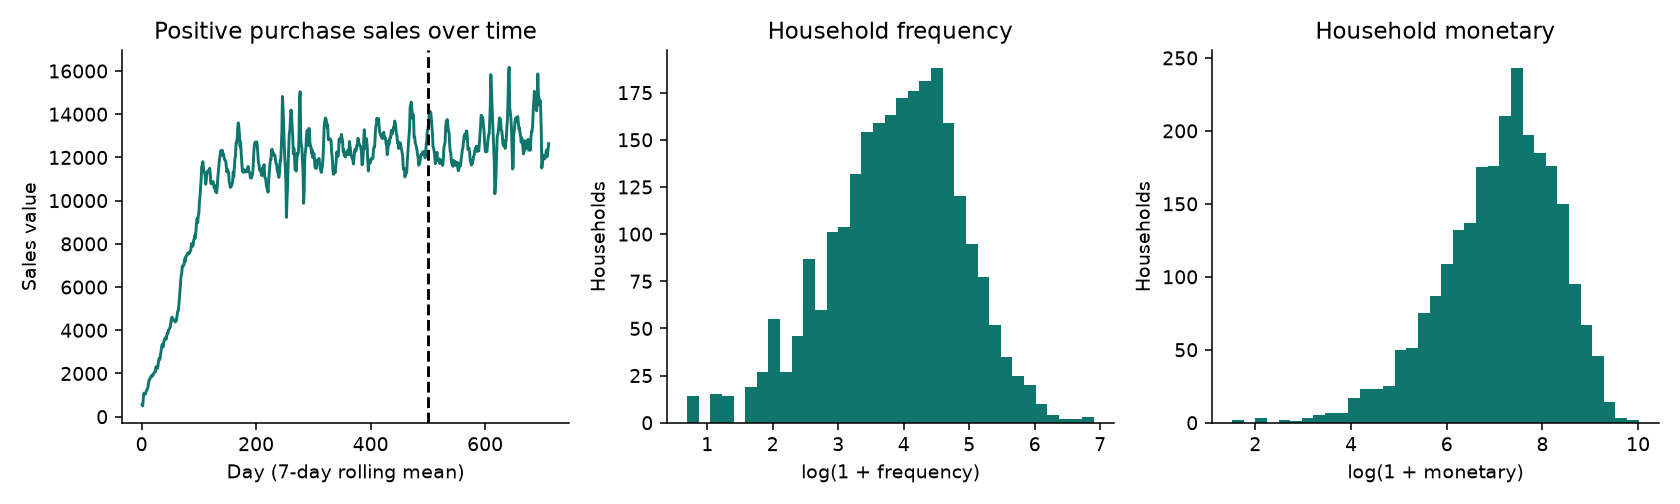

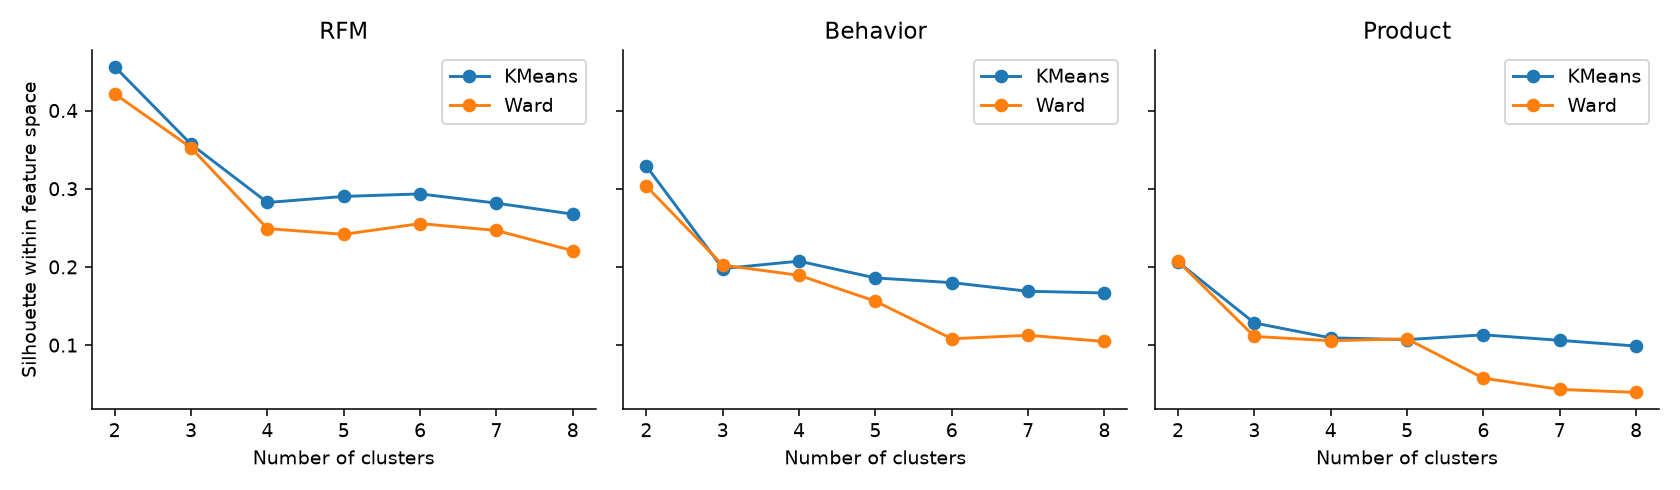

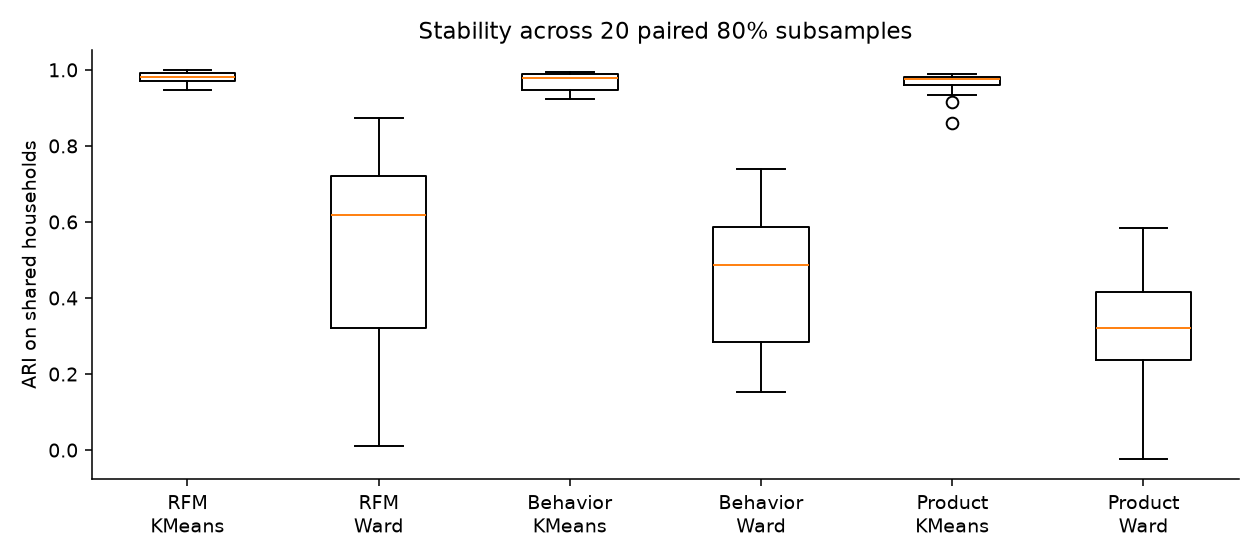

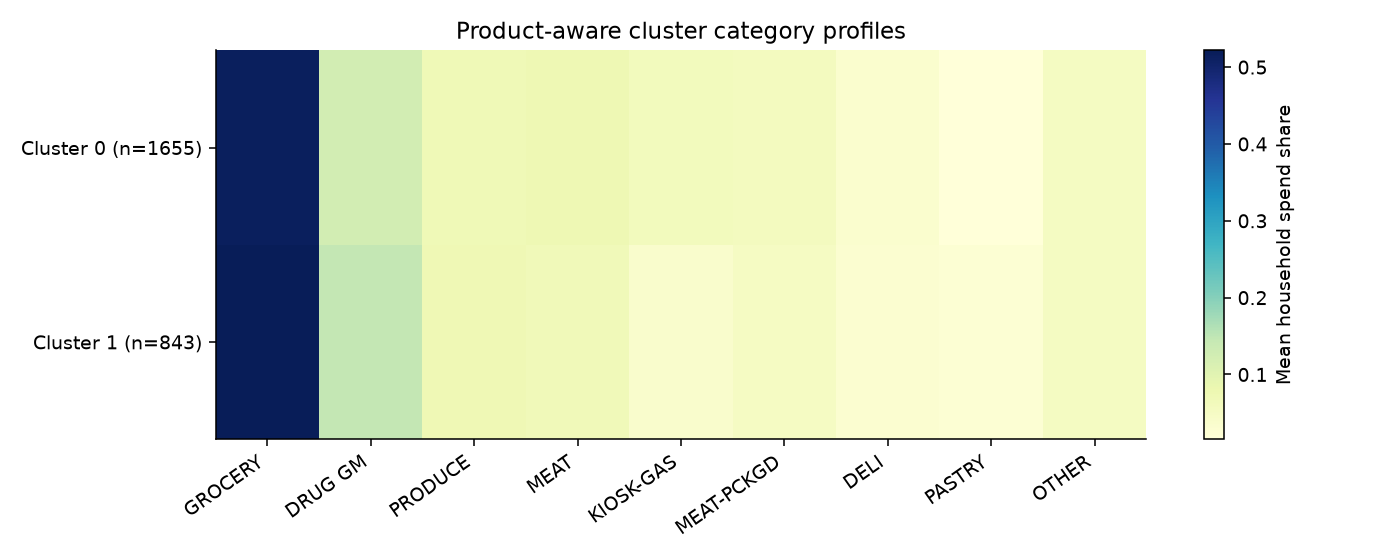

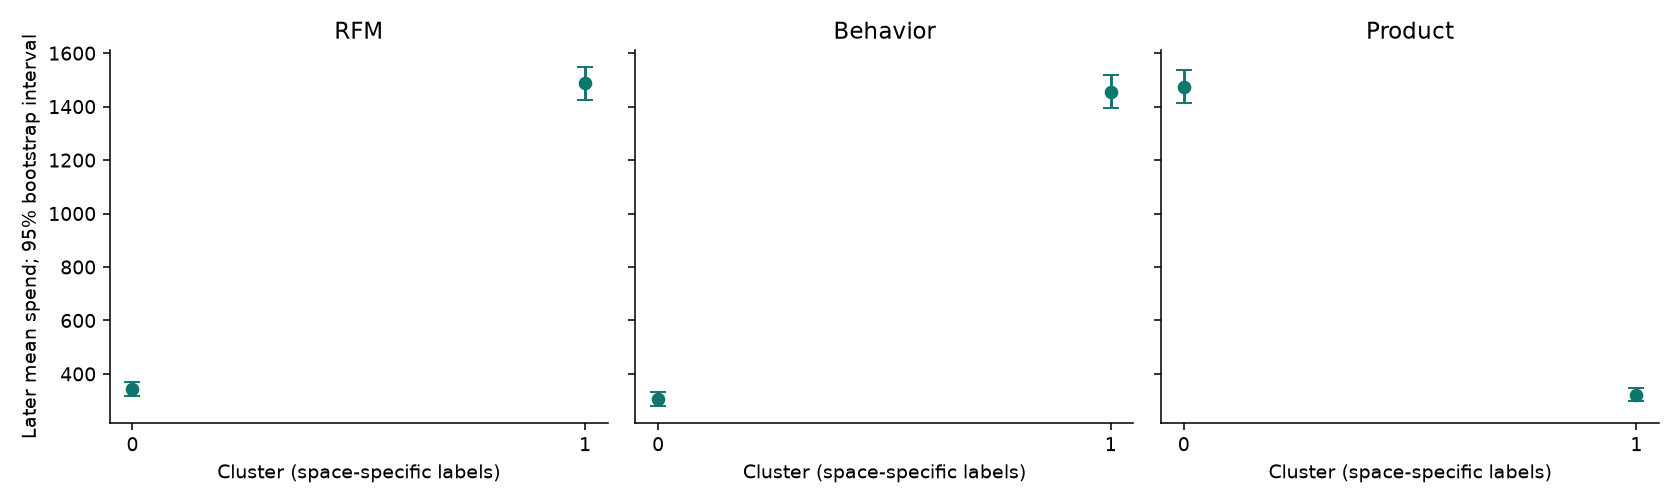

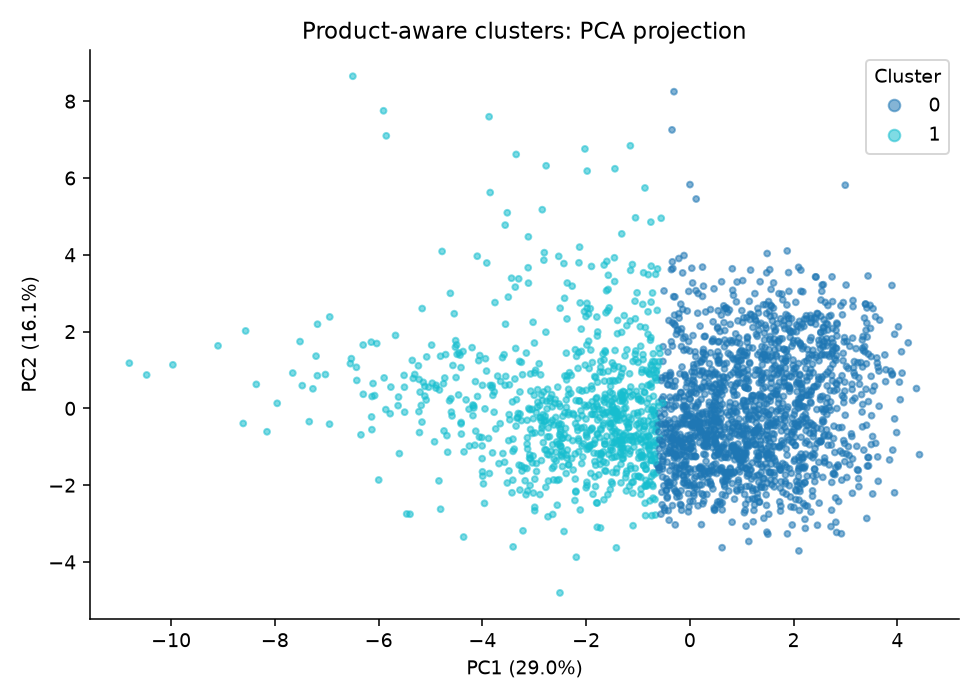

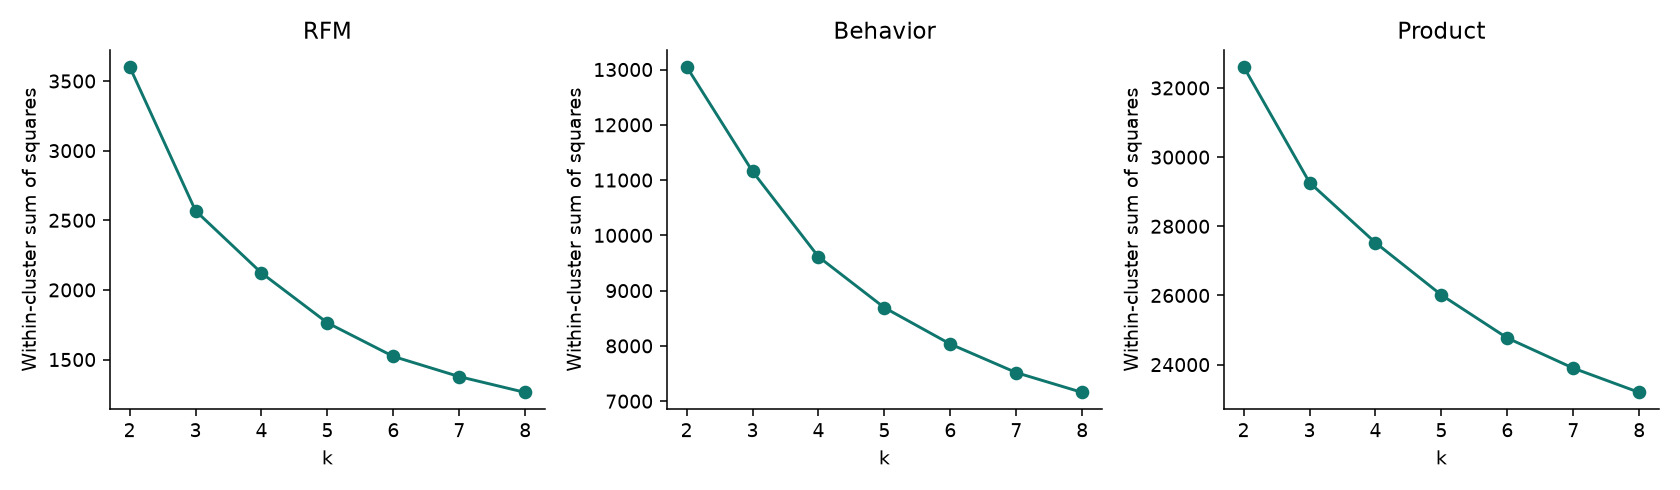

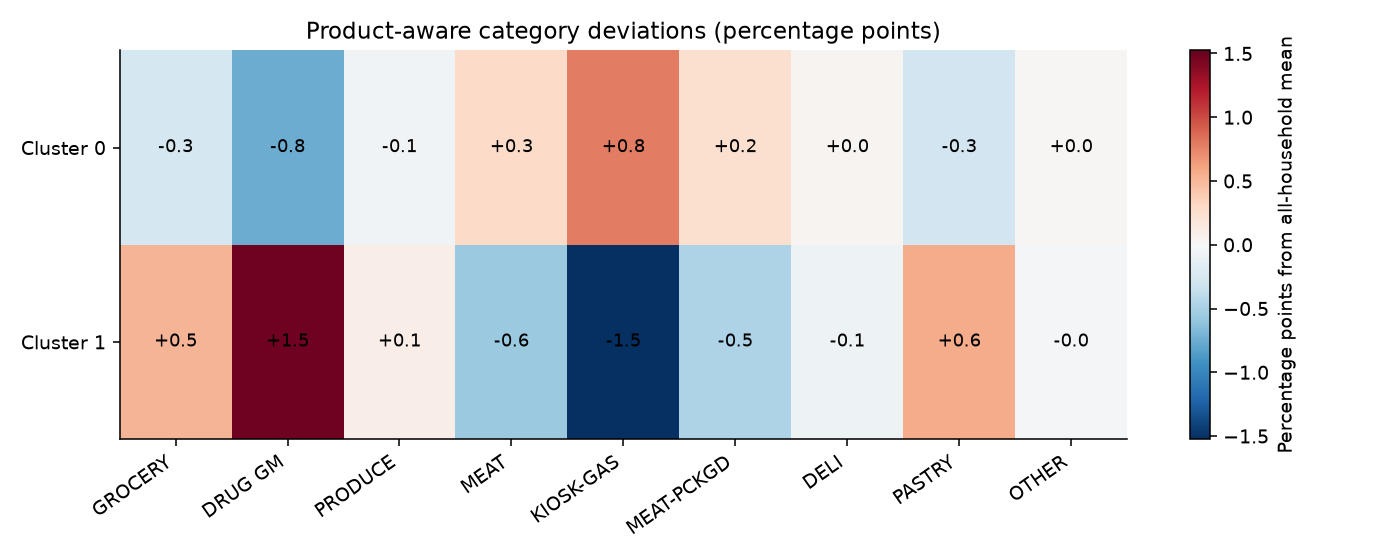

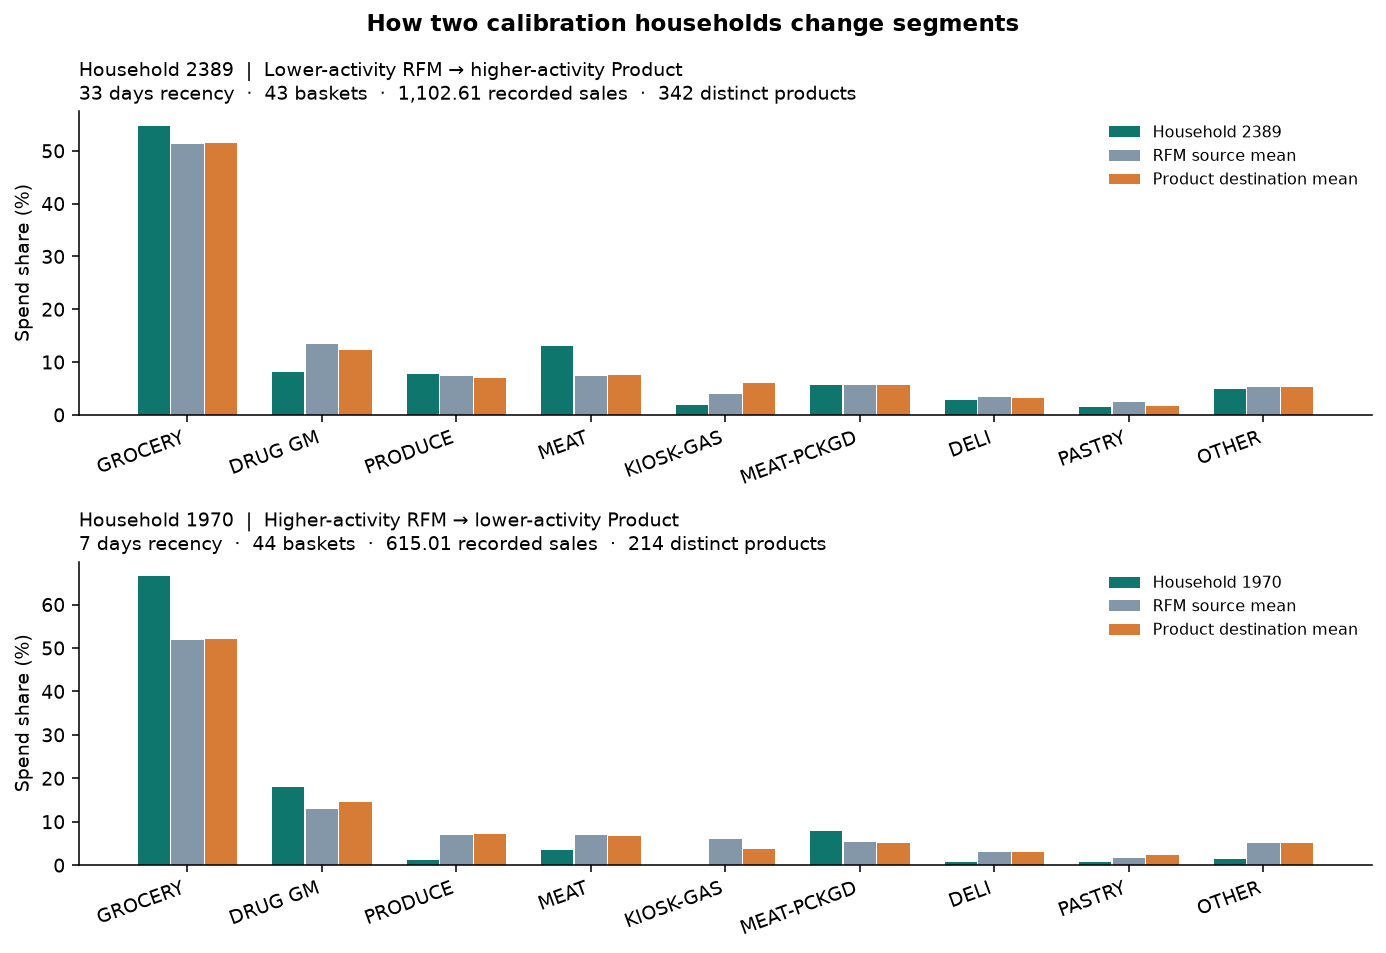

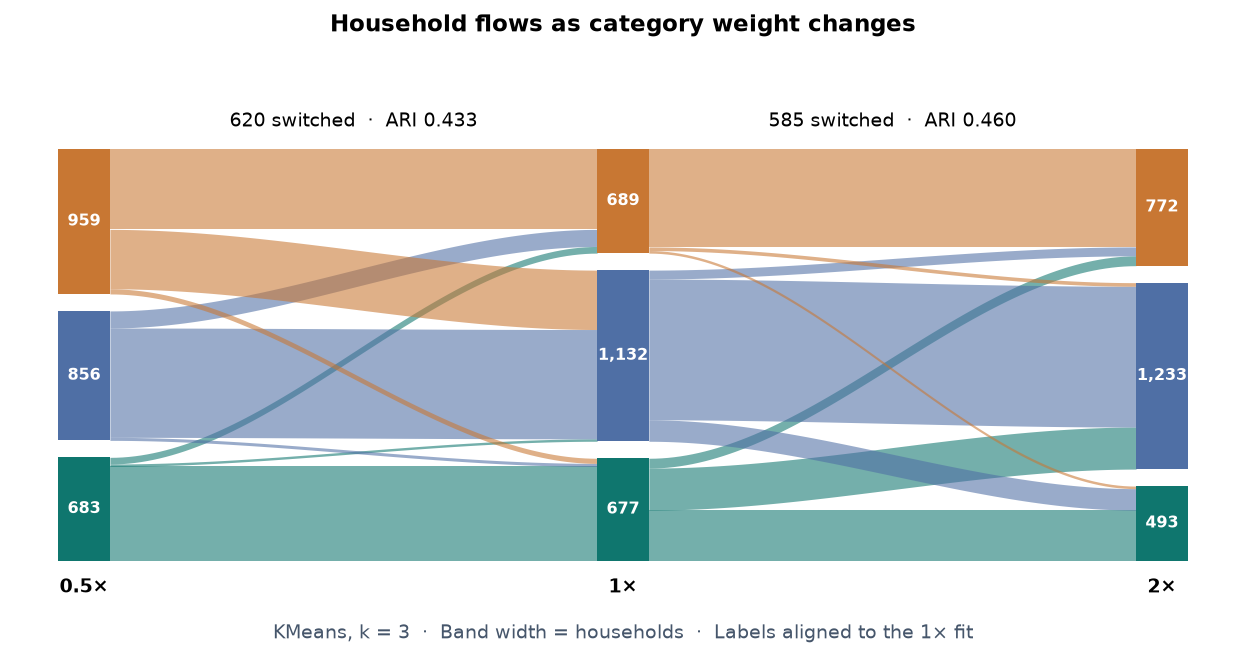

In [7]:
from IPython.display import display, Image
for file in [
    'fixed_k_metrics.csv', 'fixed_k_holdout.csv', 'common_rfm_scores.csv',
    'category_weight_sensitivity.csv', 'rfm_product_transitions.csv', 'household_cases.csv',
]:
    print(file)
    display(pd.read_csv(OUT / file))
for file in sorted(FIG.glob('*.png')):
    if not file.name.startswith('12_'):
        display(Image(filename=str(file)))

## Exploratory later-period category preferences

Frozen calibration labels group households in DAY 501–711. Each later-active household contributes one normalized recorded-sales vector using the same eight calibration departments plus OTHER. The 59 households with no later positive purchases remain in activity denominators and have no defined category composition. Calibration and holdout category profiles use the same active households, and each period's deviations are centered on its own active-cohort mean.

Category η² is the between-cluster sum of squared Euclidean deviations divided by the total, computed on raw share vectors with equal weight per household. The Product-minus-RFM contrast uses 1,000 paired resamples of the active households and a 95% percentile interval conditional on the frozen labels. Because the holdout window had already been examined for spending, this is an exploratory preference analysis. The metric evaluates observed category stratification under this geometry.

,space,k,calibration_households,active_households,calibration_category_eta_squared,future_category_eta_squared
0,RFM,2,2498,2439,0.002503,0.002992
1,Behavior,2,2498,2439,0.002206,0.001798
2,Product,2,2498,2439,0.005285,0.003860


,space,cluster,calibration_households,active_households,future_active_rate
0,RFM,0,882,828,0.938776
1,RFM,1,1616,1611,0.996906
2,Behavior,0,809,758,0.936959
3,Behavior,1,1689,1681,0.995263
4,Product,0,1655,1646,0.994562
5,Product,1,843,793,0.940688


,comparison,active_households,eta_squared_difference,conditional_ci_low,conditional_ci_high,bootstrap_draws
0,Product minus RFM,2439,0.000868,-0.001097,0.003148,1000


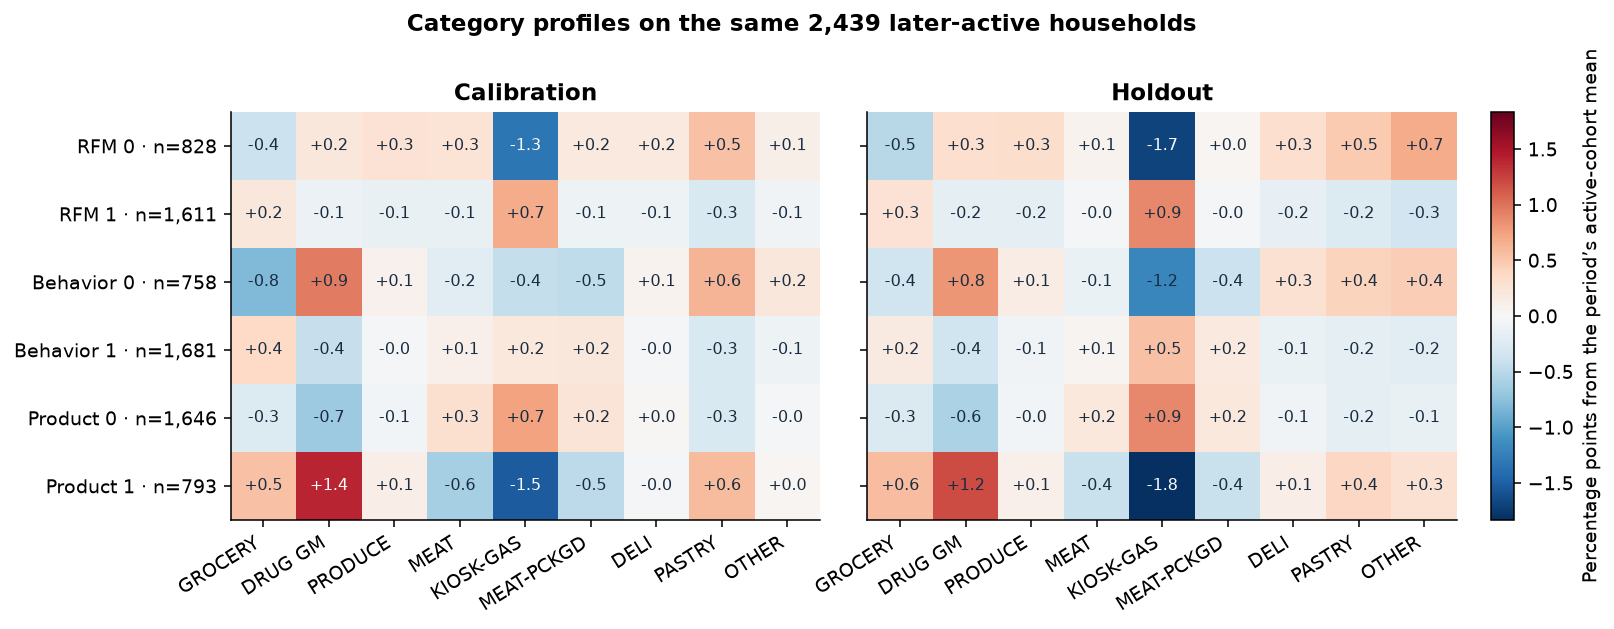

In [8]:
for file in [
    'holdout_category_summary.csv', 'holdout_category_activity.csv',
    'holdout_category_paired_difference.csv',
]:
    display(pd.read_csv(OUT / file))
display(Image(filename=str(FIG / '12_future_categories.png')))

## Interpretation and limitations

Read the generated tables before making a claim: high silhouette in one feature space cannot establish that its features are better than another space. Compare shared-space metrics, fixed-k stability, changed assignments, category interpretation, and untouched later activity together. No labels establish a uniquely correct segmentation. A two-year loyalty-panel dataset has selection and observation-window limits; DAY does not establish a calendar date. Discounts and quantity fields require care; recorded sales describe the observed table rather than profit or causal price effects. A single temporal split cannot prove transportability. Full-pipeline resampling, alternative composition geometry, additional holdout windows, and an actual intervention test are sensible future work.

**Observed conclusion:** enrichment changes household assignments but does not establish a superior segmentation. Category differences between the selected broad groups are small (roughly 1.5 percentage points at most). Category-block coordinate weighting substantially changes the k=3 partition, which limits any claim that one product-aware solution is uniquely meaningful.